<h1 style="color:red;">Road Accident Analysis</h1>

### 1. Import Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

### 2. Data Loading & Preprocessing

In [3]:
df=pd.read_csv("accident prediction.csv")
print("Dataset loaded successfully")
df.head()

Dataset loaded successfully


,State Name,City Name,Year,Month,Day of Week,Time of Day,Accident Severity,Number of Vehicles Involved,Vehicle Type Involved,Number of Casualties,...,Road Type,Road Condition,Lighting Conditions,Traffic Control Presence,Speed Limit (km/h),Driver Age,Driver Gender,Driver License Status,Alcohol Involvement,Accident Location Details
0,Jammu and Kashmir,Unknown,2021,May,Monday,01:46,Serious,5,Cycle,0,...,National Highway,Wet,Dark,Signs,61,66,Male,NaN,Yes,Curve
1,Uttar Pradesh,Lucknow,2018,January,Wednesday,21:30,Minor,5,Truck,5,...,Urban Road,Dry,Dusk,Signs,92,60,Male,NaN,Yes,Straight Road
2,Chhattisgarh,Unknown,2023,May,Wednesday,05:37,Minor,5,Pedestrian,6,...,National Highway,Under Construction,Dawn,Signs,120,26,Female,NaN,No,Bridge
3,Uttar Pradesh,Lucknow,2020,June,Saturday,00:31,Minor,3,Bus,10,...,State Highway,Dry,Dark,Signals,76,34,Female,Valid,Yes,Straight Road
4,Sikkim,Unknown,2021,August,Thursday,11:21,Minor,5,Cycle,7,...,Urban Road,Wet,Dusk,Signs,115,30,Male,NaN,No,Intersection


In [3]:
print(f"Dataset contains {df.shape[0]} rows and {df.shape[1]} columns.")

Dataset contains 3000 rows and 22 columns.


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 3000 entries, 0 to 2999
Data columns (total 22 columns):
 #   Column                       Non-Null Count  Dtype
---  ------                       --------------  -----
 0   State Name                   3000 non-null   str  
 1   City Name                    3000 non-null   str  
 2   Year                         3000 non-null   int64
 3   Month                        3000 non-null   str  
 4   Day of Week                  3000 non-null   str  
 5   Time of Day                  3000 non-null   str  
 6   Accident Severity            3000 non-null   str  
 7   Number of Vehicles Involved  3000 non-null   int64
 8   Vehicle Type Involved        3000 non-null   str  
 9   Number of Casualties         3000 non-null   int64
 10  Number of Fatalities         3000 non-null   int64
 11  Weather Conditions           3000 non-null   str  
 12  Road Type                    3000 non-null   str  
 13  Road Condition               3000 non-null   str  
 14  Lig

In [5]:
df.describe()

,Year,Number of Vehicles Involved,Number of Casualties,Number of Fatalities,Speed Limit (km/h),Driver Age
count,3000.000000,3000.000000,3000.000000,3000.000000,3000.000000,3000.00000
mean,2020.530000,2.996000,5.066000,2.455333,74.940667,44.17700
std,1.683858,1.428285,3.214097,1.717650,26.765088,15.40286
min,2018.000000,1.000000,0.000000,0.000000,30.000000,18.00000
25%,2019.000000,2.000000,2.000000,1.000000,51.000000,31.00000
50%,2021.000000,3.000000,5.000000,2.000000,75.000000,45.00000
75%,2022.000000,4.000000,8.000000,4.000000,99.000000,57.00000
max,2023.000000,5.000000,10.000000,5.000000,120.000000,70.00000


### 3. Checking Missing Values

In [6]:
df.isnull().sum()

State Name                       0
City Name                        0
Year                             0
Month                            0
Day of Week                      0
Time of Day                      0
Accident Severity                0
Number of Vehicles Involved      0
Vehicle Type Involved            0
Number of Casualties             0
Number of Fatalities             0
Weather Conditions               0
Road Type                        0
Road Condition                   0
Lighting Conditions              0
Traffic Control Presence       716
Speed Limit (km/h)               0
Driver Age                       0
Driver Gender                    0
Driver License Status          975
Alcohol Involvement              0
Accident Location Details        0
dtype: int64

### 4. Handling Missing Values

In [7]:
df.isnull().sum()/(len(df))*100

State Name                      0.000000
City Name                       0.000000
Year                            0.000000
Month                           0.000000
Day of Week                     0.000000
Time of Day                     0.000000
Accident Severity               0.000000
Number of Vehicles Involved     0.000000
Vehicle Type Involved           0.000000
Number of Casualties            0.000000
Number of Fatalities            0.000000
Weather Conditions              0.000000
Road Type                       0.000000
Road Condition                  0.000000
Lighting Conditions             0.000000
Traffic Control Presence       23.866667
Speed Limit (km/h)              0.000000
Driver Age                      0.000000
Driver Gender                   0.000000
Driver License Status          32.500000
Alcohol Involvement             0.000000
Accident Location Details       0.000000
dtype: float64

In [8]:
df.columns

Index(['State Name', 'City Name', 'Year', 'Month', 'Day of Week',
       'Time of Day', 'Accident Severity', 'Number of Vehicles Involved',
       'Vehicle Type Involved', 'Number of Casualties', 'Number of Fatalities',
       'Weather Conditions', 'Road Type', 'Road Condition',
       'Lighting Conditions', 'Traffic Control Presence', 'Speed Limit (km/h)',
       'Driver Age', 'Driver Gender', 'Driver License Status',
       'Alcohol Involvement', 'Accident Location Details'],
      dtype='str')

In [9]:
df['Traffic Control Presence']=df['Traffic Control Presence'].fillna(df['Traffic Control Presence'].mode() [0])


In [10]:
df['Driver License Status'] = df['Driver License Status'].fillna(df['Driver License Status'].mode()[0])

In [11]:
df.isnull().sum()

State Name                     0
City Name                      0
Year                           0
Month                          0
Day of Week                    0
Time of Day                    0
Accident Severity              0
Number of Vehicles Involved    0
Vehicle Type Involved          0
Number of Casualties           0
Number of Fatalities           0
Weather Conditions             0
Road Type                      0
Road Condition                 0
Lighting Conditions            0
Traffic Control Presence       0
Speed Limit (km/h)             0
Driver Age                     0
Driver Gender                  0
Driver License Status          0
Alcohol Involvement            0
Accident Location Details      0
dtype: int64

### 5. Check for Duplicates

In [12]:
df.duplicated().sum()

np.int64(0)

In [13]:
df.dtypes

State Name                       str
City Name                        str
Year                           int64
Month                            str
Day of Week                      str
Time of Day                      str
Accident Severity                str
Number of Vehicles Involved    int64
Vehicle Type Involved            str
Number of Casualties           int64
Number of Fatalities           int64
Weather Conditions               str
Road Type                        str
Road Condition                   str
Lighting Conditions              str
Traffic Control Presence         str
Speed Limit (km/h)             int64
Driver Age                     int64
Driver Gender                    str
Driver License Status            str
Alcohol Involvement              str
Accident Location Details        str
dtype: object

### Data Cleaning Completed

In [14]:
df.head()

,State Name,City Name,Year,Month,Day of Week,Time of Day,Accident Severity,Number of Vehicles Involved,Vehicle Type Involved,Number of Casualties,...,Road Type,Road Condition,Lighting Conditions,Traffic Control Presence,Speed Limit (km/h),Driver Age,Driver Gender,Driver License Status,Alcohol Involvement,Accident Location Details
0,Jammu and Kashmir,Unknown,2021,May,Monday,01:46,Serious,5,Cycle,0,...,National Highway,Wet,Dark,Signs,61,66,Male,Valid,Yes,Curve
1,Uttar Pradesh,Lucknow,2018,January,Wednesday,21:30,Minor,5,Truck,5,...,Urban Road,Dry,Dusk,Signs,92,60,Male,Valid,Yes,Straight Road
2,Chhattisgarh,Unknown,2023,May,Wednesday,05:37,Minor,5,Pedestrian,6,...,National Highway,Under Construction,Dawn,Signs,120,26,Female,Valid,No,Bridge
3,Uttar Pradesh,Lucknow,2020,June,Saturday,00:31,Minor,3,Bus,10,...,State Highway,Dry,Dark,Signals,76,34,Female,Valid,Yes,Straight Road
4,Sikkim,Unknown,2021,August,Thursday,11:21,Minor,5,Cycle,7,...,Urban Road,Wet,Dusk,Signs,115,30,Male,Valid,No,Intersection


### 6. Feature Engineering

In [15]:
# Create time period feature
hour = pd.to_datetime(
    df["Time of Day"], format="%H:%M"
).dt.hour

df["Time Period"] = np.select(
    [
        hour < 6,
        hour < 12,
        hour < 17,
        hour < 21
    ],
    [
        "Night",
        "Morning",
        "Afternoon",
        "Evening"
    ],
    default="Night"
)

# Create driver age groups
df["Driver Age Group"] = pd.cut( df["Driver Age"], bins=[0, 25, 45, 60, float("inf")], labels=["Young", "Adult", "Middle-aged", "Senior"])

# Create fatality status
df["Fatality Status"] = np.where(df["Number of Fatalities"] > 0, "Fatality Present", "No Fatality")

# Create casualty status
df["Casualty Status"] = np.where(df["Number of Casualties"] > 0, "Casualties Present","No Casualties")

# Create adverse weather indicator
df["Adverse Weather"] = np.where(df["Weather Conditions"].str.lower().isin( ["rainy", "foggy", "stormy"] ), "Adverse Weather","Other Weather")

# Display the new features
df.head()

,State Name,City Name,Year,Month,Day of Week,Time of Day,Accident Severity,Number of Vehicles Involved,Vehicle Type Involved,Number of Casualties,...,Driver Age,Driver Gender,Driver License Status,Alcohol Involvement,Accident Location Details,Time Period,Driver Age Group,Fatality Status,Casualty Status,Adverse Weather
0,Jammu and Kashmir,Unknown,2021,May,Monday,01:46,Serious,5,Cycle,0,...,66,Male,Valid,Yes,Curve,Night,Senior,Fatality Present,No Casualties,Other Weather
1,Uttar Pradesh,Lucknow,2018,January,Wednesday,21:30,Minor,5,Truck,5,...,60,Male,Valid,Yes,Straight Road,Night,Middle-aged,Fatality Present,Casualties Present,Other Weather
2,Chhattisgarh,Unknown,2023,May,Wednesday,05:37,Minor,5,Pedestrian,6,...,26,Female,Valid,No,Bridge,Night,Adult,Fatality Present,Casualties Present,Adverse Weather
3,Uttar Pradesh,Lucknow,2020,June,Saturday,00:31,Minor,3,Bus,10,...,34,Female,Valid,Yes,Straight Road,Night,Adult,Fatality Present,Casualties Present,Adverse Weather
4,Sikkim,Unknown,2021,August,Thursday,11:21,Minor,5,Cycle,7,...,30,Male,Valid,No,Intersection,Morning,Adult,Fatality Present,Casualties Present,Adverse Weather


In [16]:
df[["Time of Day", "Time Period"]].head(10)

,Time of Day,Time Period
0,01:46,Night
1,21:30,Night
2,05:37,Night
3,00:31,Night
4,11:21,Morning
5,08:04,Morning
6,18:55,Evening
7,11:40,Morning
8,08:26,Morning
9,02:01,Night


In [17]:
df["Time Period"].value_counts()

Time Period
Night        1172
Morning       761
Afternoon     597
Evening       470
Name: count, dtype: int64

## 7. Data Visualization

### A. Time Period Analysis

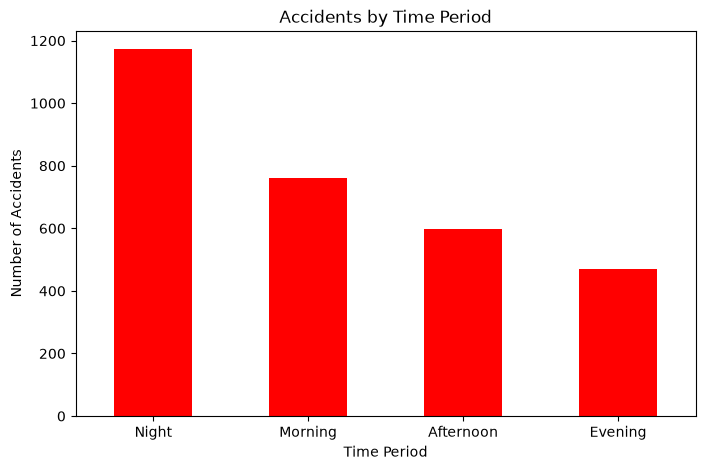

In [18]:
df["Time Period"].value_counts().plot(
    kind="bar", color='red',
    figsize=(8, 5)
)

plt.title("Accidents by Time Period")
plt.xlabel("Time Period")
plt.ylabel("Number of Accidents")
plt.xticks(rotation=0)
plt.show()

## Insights

### 1. Accidents by Time Period
#### - Night-1,172
#### - Morning-761
#### - Afternoon-597
#### - Evening- 470
#### The highest number of recorded accidents occurred during the night, while the lowest number occurred during the evening.

### B. Accident Severity Analysis

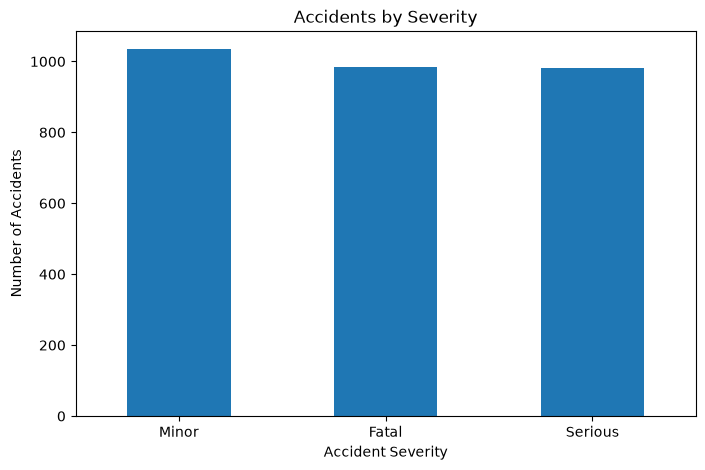

In [19]:
df["Accident Severity"].value_counts().plot(
    kind="bar",
    figsize=(8, 5)
)

plt.title("Accidents by Severity")
plt.xlabel("Accident Severity")
plt.ylabel("Number of Accidents")
plt.xticks(rotation=0)
plt.show()

## Insights
### 2. Accidents by Severity
#### - Minor: 1,034
#### - Fatal: 985
#### - Serious: 981
 #### Insight Minor accidents form the largest category, with 1,034 records. Fatal and serious accidents have relatively similar counts.

### C. State-Wise Accident Analysis

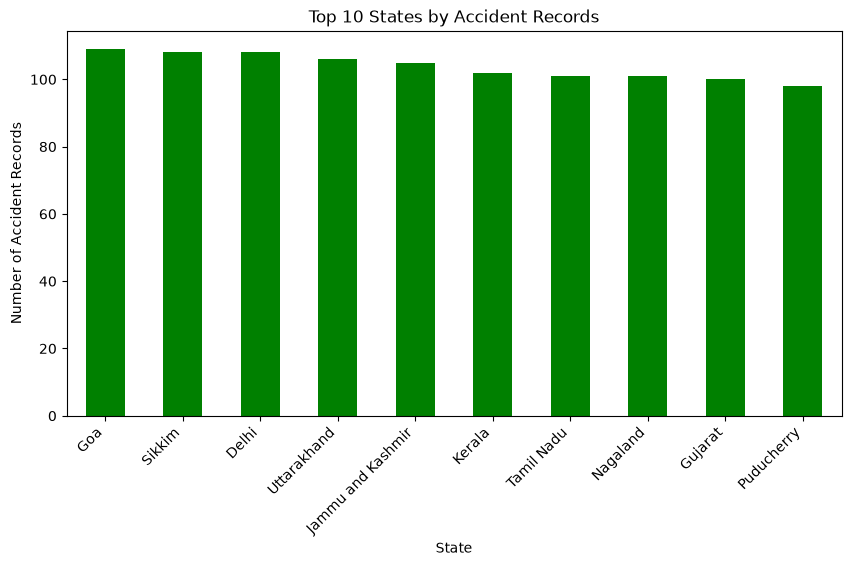

In [20]:
df["State Name"].value_counts().head(10).plot( kind="bar", figsize=(10, 5), color='green')
plt.title("Top 10 States by Accident Records")
plt.xlabel("State")
plt.ylabel("Number of Accident Records")
plt.xticks(rotation=45, ha="right")
plt.show()

## Insights
### 3. Top 10 States by Accident Records
#### - Goa has the highest count among the states, with 109 records.
#### - Sikkim and Delhi have 108 records each.
#### - Uttarakhand has 106 records.
#### - Jammu and Kashmir has 105 records.
#### - Puducherry has the lowest count among the displayed top 10, with 98 records.
#### Goa has the highest number of recorded accidents among the top 10 states in this dataset. These are dataset counts, not necessarily actual statewide accident rates.

### D. Accident Records by Weather Conditions

In [21]:
df['Weather Conditions']

0         Hazy
1         Hazy
2        Foggy
3        Rainy
4        Foggy
         ...  
2995     Foggy
2996      Hazy
2997     Rainy
2998    Stormy
2999      Hazy
Name: Weather Conditions, Length: 3000, dtype: str

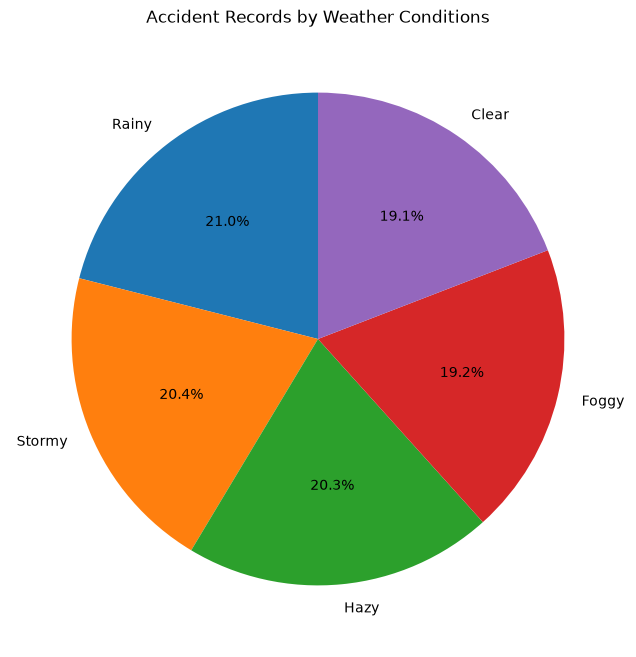

In [22]:
weather_counts = df["Weather Conditions"].value_counts()

plt.figure(figsize=(8, 8))

plt.pie(weather_counts, labels=weather_counts.index,autopct="%1.1f%%", startangle=90
)

plt.title("Accident Records by Weather Conditions")
plt.show()

## Insights
### 4. Accident Records by Weather Conditions
#### - Rainy: 631
#### - Stormy: 611
#### - Hazy: 608
#### - Foggy: 576
#### - Clear: 574
####  Rainy weather has the highest number of accident records, while clear weather has the lowest. The difference in counts does not establish that weather caused the accidents.

### E. Accident Records by Road Condition

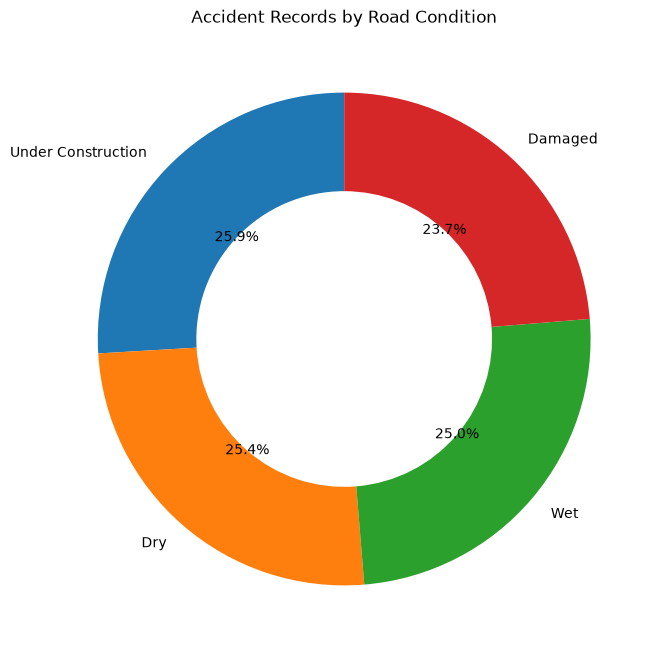

In [23]:
road_counts = df["Road Condition"].value_counts()

plt.figure(figsize=(8, 8))

plt.pie(
    road_counts,
    labels=road_counts.index,
    autopct="%1.1f%%",
    startangle=90,
    wedgeprops={"width": 0.4}
)

plt.title("Accident Records by Road Condition")
plt.show()

## Insights
### 5. Accident Records by Road Condition
#### - Under Construction: 778
#### - Dry: 761
#### - Wet: 750
#### - Damaged: 711
#### The highest number of accident records occurred on roads categorized as under construction, while damaged roads had the lowest count among the four categories.

### E. Monthly Accident Analysis

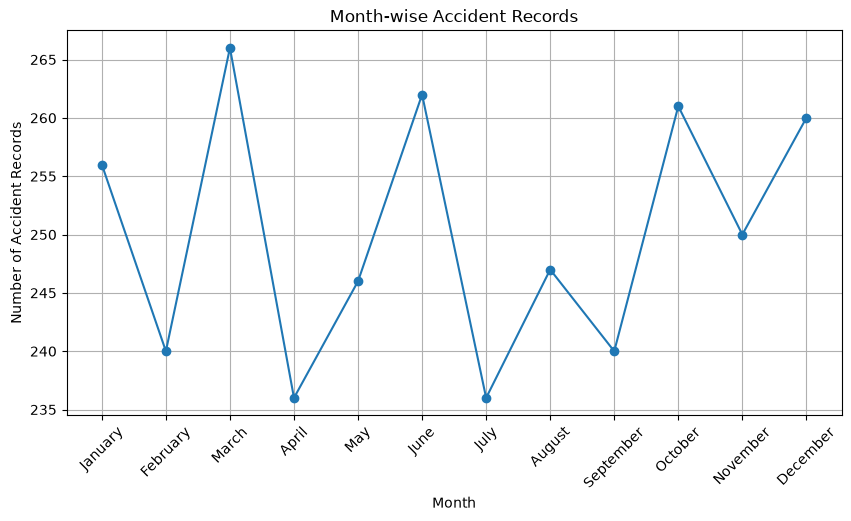

In [24]:
month_order = [
    "January", "February", "March", "April",
    "May", "June", "July", "August",
    "September", "October", "November", "December"
]

month_counts = df["Month"].value_counts().reindex(month_order)

plt.figure(figsize=(10, 5))

plt.plot(
    month_counts.index,
    month_counts.values,
    marker="o"
)

plt.title("Month-wise Accident Records")
plt.xlabel("Month")
plt.ylabel("Number of Accident Records")
plt.xticks(rotation=45)
plt.grid(True)
plt.show()

## Insights
## 6. Month-wise Accident Records
#### - March: 266 — highest
#### - June: 262
#### - October: 261
#### - December: 260
#### - July and April: 236 each — lowest
#### March has the highest number of recorded accidents, while April and July have the lowest counts. The monthly differences are relatively small.

### F. Accident Severity vs Time Period

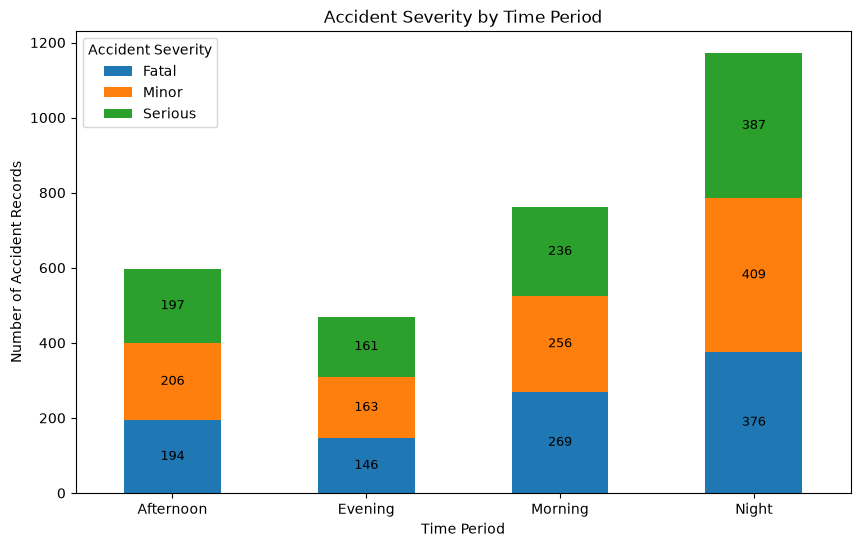

In [25]:
severity_time = pd.crosstab(df["Time Period"], df["Accident Severity"])

ax = severity_time.plot(kind="bar",stacked=True,figsize=(10, 6))

# Show record counts on each section
for container in ax.containers:
    ax.bar_label(container, label_type="center", fontsize=9)
    
plt.title("Accident Severity by Time Period")
plt.xlabel("Time Period")
plt.ylabel("Number of Accident Records")
plt.xticks(rotation=0)
plt.legend(title="Accident Severity")
plt.show()

## Insights
### 7. Accident Severity by Time Period
#### Night has the highest counts for Fatal, Minor, and Serious accidents. Evening has the lowest counts across all three categories.

### G. Driver Age Group Analysis

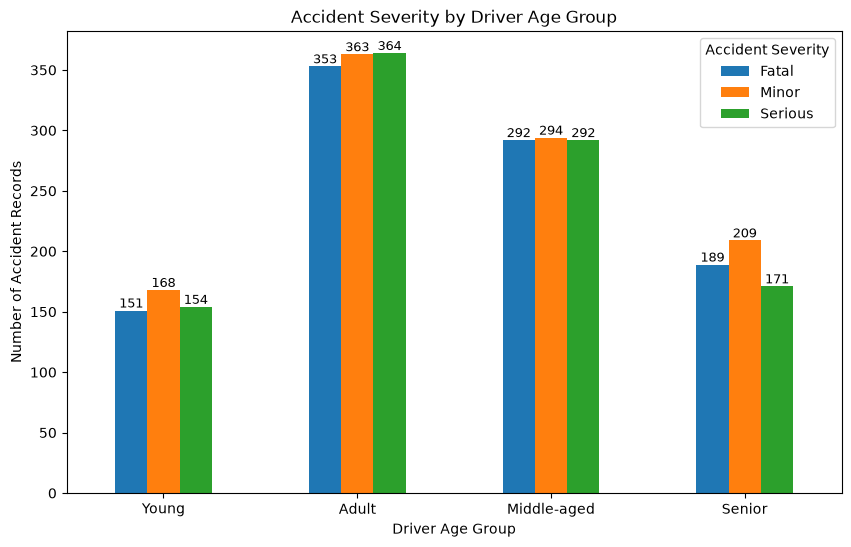

In [26]:
age_severity = pd.crosstab( df["Driver Age Group"], df["Accident Severity"])

ax = age_severity.plot( kind="bar", figsize=(10, 6))

# Display record counts on each bar
for container in ax.containers:
    ax.bar_label(container, fontsize=9)

plt.title("Accident Severity by Driver Age Group")
plt.xlabel("Driver Age Group")
plt.ylabel("Number of Accident Records")
plt.xticks(rotation=0)
plt.legend(title="Accident Severity")
plt.show()

## Insights
### 8. Driver Age Group vs Accident Severity
#### The Adult group has the highest number of accident records in all three severity categories. However, this shows counts rather than the risk of accidents for each age group.

### H. Vehicle Type Analysis

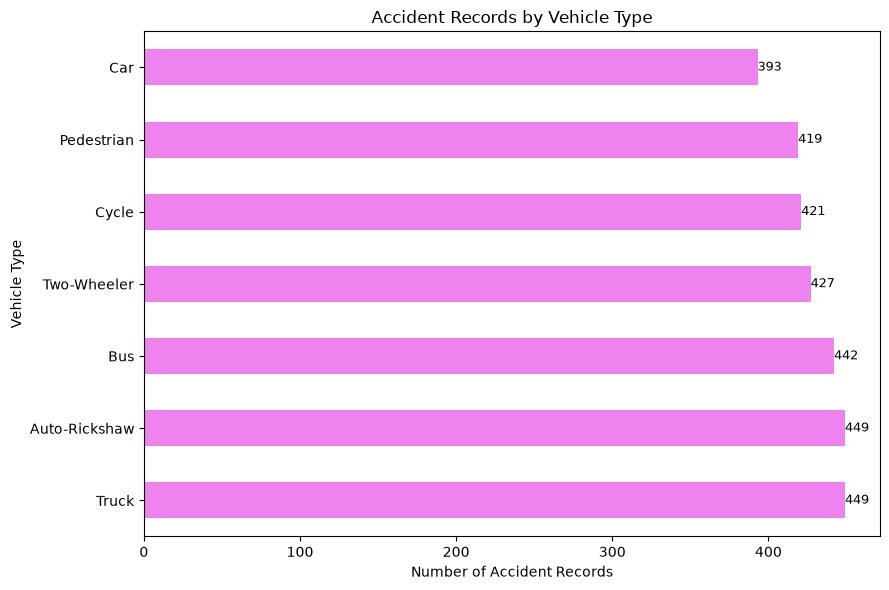

In [27]:
vehicle_counts = df["Vehicle Type Involved"].value_counts()

ax = vehicle_counts.plot(kind="barh", figsize=(9, 6), color='violet')

ax.bar_label(ax.containers[0], fontsize=9)

plt.title("Accident Records by Vehicle Type")
plt.xlabel("Number of Accident Records")
plt.ylabel("Vehicle Type")
plt.tight_layout()
plt.show()

## Insights
### 9. Accident Records by Vehicle Type
#### - Truck: 449
#### - Auto-Rickshaw: 449
#### - Bus: 442
#### - Two-Wheeler: 427
#### - Cycle: 421
#### - Pedestrian: 419
#### - Car: 393
### Trucks and auto-rickshaws share the highest count, with 449 records each. Cars have the lowest count, at 393 records.

## Relationship Analysis

### I.Alcohol Involvement vs Accident Severity

In [28]:
alcohol_severity = pd.crosstab(
    df["Alcohol Involvement"],
    df["Accident Severity"]
)
alcohol_severity["Total"] = alcohol_severity.sum(axis=1)

print(alcohol_severity)

Accident Severity    Fatal  Minor  Serious  Total
Alcohol Involvement                              
No                     484    522      474   1480
Yes                    501    512      507   1520


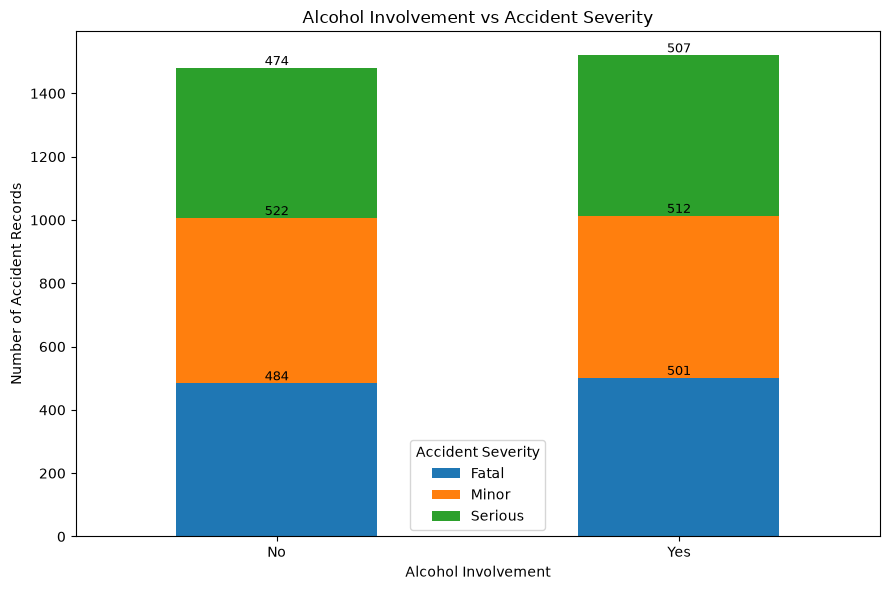

In [29]:
alcohol_severity = pd.crosstab(
    df["Alcohol Involvement"],
    df["Accident Severity"]
)

ax = alcohol_severity.plot(
    kind="bar",
    stacked=True,
    figsize=(9, 6)
)
# Display record counts on each bar
for container in ax.containers:
    ax.bar_label(container, fontsize=9)

plt.title("Alcohol Involvement vs Accident Severity")
plt.xlabel("Alcohol Involvement")
plt.ylabel("Number of Accident Records")
plt.xticks(rotation=0)
plt.legend(title="Accident Severity")
plt.tight_layout()
plt.show()

## Insights 
### 10. Alcohol Involvement vs Accident Severity
#### The number of records in each severity category is relatively similar between the two alcohol-involvement groups. The alcohol-involved group has slightly more fatal and serious records, while the non-alcohol group has slightly more minor records.

### J. Day of Week vs Time Period

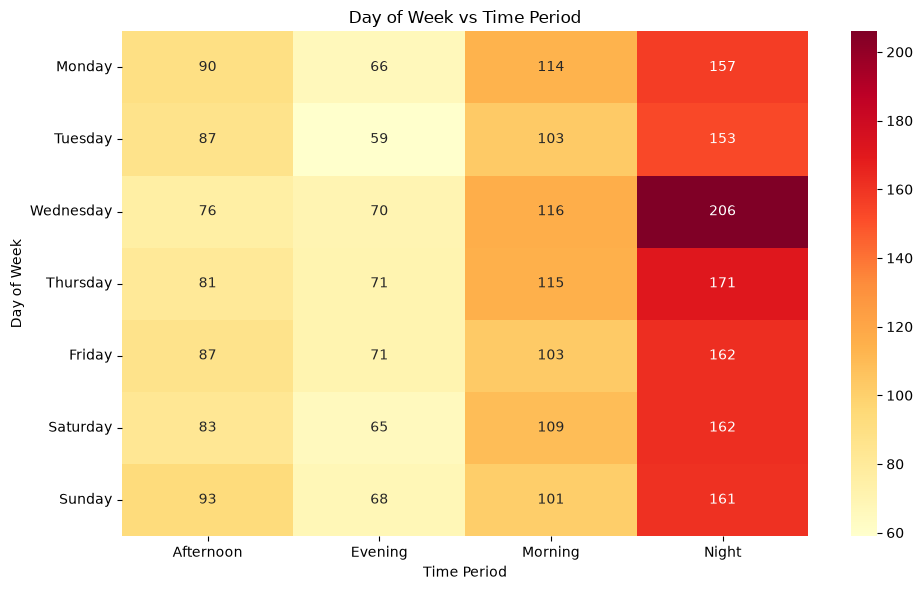

In [30]:

# Count accidents by day and time period
accident_count = pd.crosstab(
    df["Day of Week"],
    df["Time Period"]
)

days_order = [
    "Monday", "Tuesday", "Wednesday",
    "Thursday", "Friday", "Saturday", "Sunday"
]

accident_count = accident_count.reindex(days_order)
# Create heatmap
plt.figure(figsize=(10, 6))

sns.heatmap(
    accident_count,
    annot=True,
    fmt="d",
    cmap="YlOrRd"
)

plt.title("Day of Week vs Time Period")
plt.xlabel("Time Period")
plt.ylabel("Day of Week")
plt.tight_layout()
plt.show()


## Insights
### 11. Day of Week vs Time Period — Heatmap
### The heatmap counts show:
#### - Wednesday night: 206 — highest day-time combination.
#### - Monday night: 157.
#### - Tuesday night: 153.
#### - Wednesday afternoon: 76.
#### - Tuesday evening: 59 — lowest day-time combination.
#### Wednesday night has the highest accident count among the day-time combinations. Tuesday evening has the lowest. This identifies patterns in the available records, not the probability of an accident occurring.

## Insights
### 12. Lighting Conditions vs Accident Severity
#### Daylight has the highest fatal-accident percentage (34.8%) among the lighting categories. Dawn has the lowest fatal percentage (30.5%). The distributions are relatively similar across conditions.

In [33]:
# Lighting Conditions vs Accident Severity

lighting_table = pd.crosstab(
    df["Lighting Conditions"],
    df["Accident Severity"],
    normalize="index"
) * 100

lighting_table = lighting_table.round(1)

print("Lighting Conditions vs Accident Severity (%)")
display(lighting_table)

Lighting Conditions vs Accident Severity (%)


Accident Severity,Fatal,Minor,Serious
Lighting Conditions,,,
Dark,33.3,33.9,32.8
Dawn,30.5,35.3,34.2
Daylight,34.8,33.5,31.7
Dusk,32.7,35.2,32.1


### 14. Monthly Accident Severity Trend

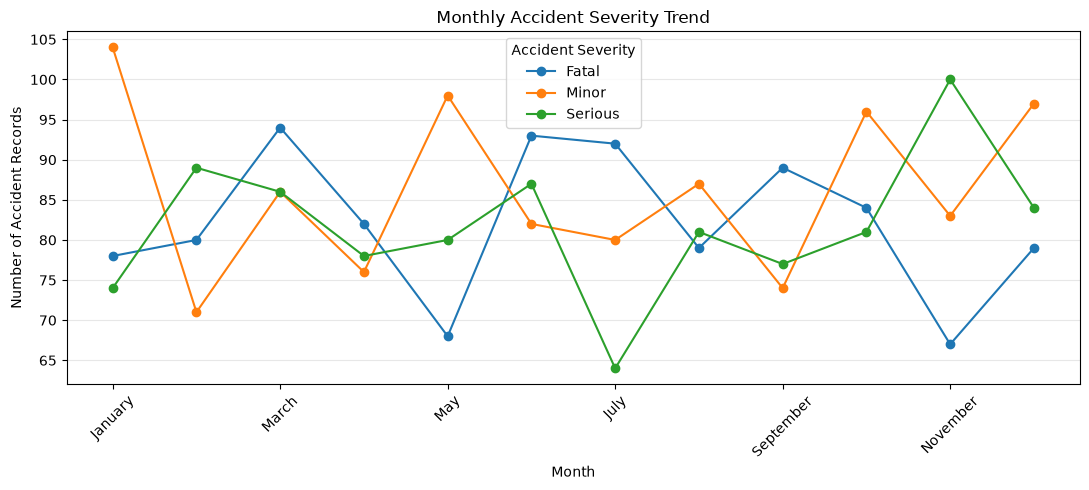

In [34]:
month_order = ["January", "February", "March", "April", "May", "June",
               "July", "August", "September", "October", "November", "December"]
monthly_severity = pd.crosstab(df["Month"], df["Accident Severity"]).reindex(month_order)
monthly_severity.plot(kind="line", marker="o", figsize=(11, 5))
plt.title("Monthly Accident Severity Trend")
plt.xlabel("Month")
plt.ylabel("Number of Accident Records")
plt.xticks(rotation=45)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

### 16. Correlation Heatmap of Numeric Features

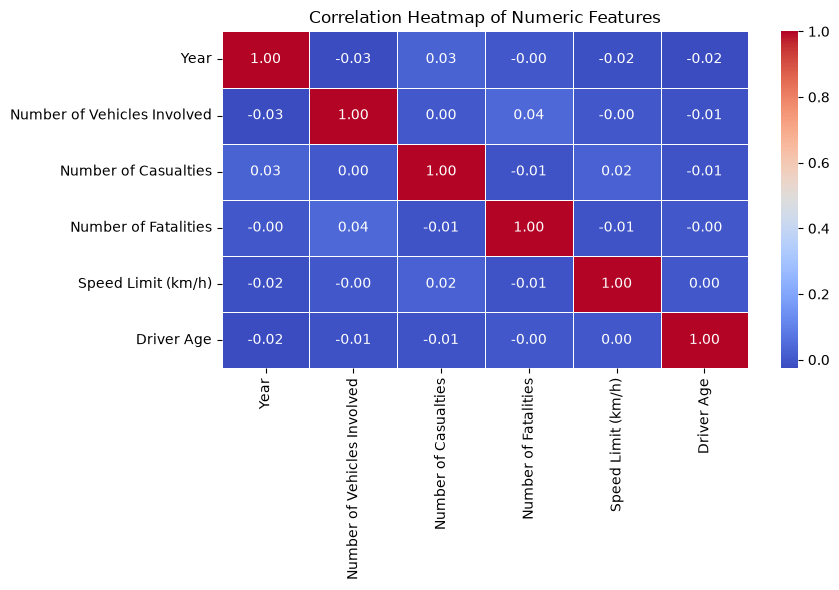

In [39]:
numeric_columns = ["Year", "Number of Vehicles Involved", "Number of Casualties",
                   "Number of Fatalities", "Speed Limit (km/h)", "Driver Age"]
numeric_columns = [col for col in numeric_columns if col in df.columns]
correlation = df[numeric_columns].corr()
plt.figure(figsize=(9, 6))
sns.heatmap(correlation, annot=True, cmap="coolwarm", fmt=".2f", linewidths=0.5)
plt.title("Correlation Heatmap of Numeric Features")
plt.tight_layout()
plt.show()

In [40]:
print("Visualization Completed")

Visualization Completed
